# Bloc 5 — Mesurer et choisir une politique (21 min)

**Situation.** Le tri annoncé à 87 % sur dev est mis en service. Sur des messages que personne n'avait regardés, le résultat est nettement plus bas, et certaines erreurs sont « sûres d'elles » (*« Netflix ne se lance plus sur le décodeur »* → résiliation, marge 0,94). Question de la direction : automatiser tout, ou rien ?

Ce notebook rejoue cette situation : options **figées**, un paquet de messages **jamais regardés**, et la question de la direction.

1. On **fige** les options (celles de `at.OPTIONS`).
2. On ouvre **une seule fois** le **test scellé** (77 messages jamais utilisés pour écrire les options ; 25 en *mode rapide*).
3. On mesure : exactitude, **intervalle de confiance**, **calibration**.
4. On construit la politique : **automatiser** quand la marge est assez grande, sinon **un humain**. Chaque table choisit son seuil.

In [1]:
# Préparation (rien à modifier) — exécutez avec Maj+Entrée
import sys; sys.path.insert(0, "..")   # le paquet atelier/ (installé par installer.sh ; ceci au cas où)
import matplotlib.pyplot as plt
import pandas as pd
import wyat
import atelier as at                  # même boîte à outils que la commande `atelier` et les exemples/
pd.set_option("display.max_colwidth", 90)
modele = at.charger_modele()

Modèle chargé en 2.7 s  (backend=mlx, device=gpu-apple, id=fork-197dbfe273512031109…)
Vitesse mesurée : ≈ 0.16 s par message.


## 1. Résultat sur le test scellé

In [2]:
test = at.lire("test_scelle.csv")
rapport_test, res_test = at.evaluer(modele, test, at.OPTIONS)
acc, bas, haut = at.intervalle_bootstrap(res_test.correct)
acc_l, bas_l, haut_l = at.intervalle_bootstrap(res_test.acceptable)
print(f"Exactitude stricte     : {acc:.1%}   IC 95 % bootstrap [{bas:.1%} ; {haut:.1%}]   (n = {len(res_test)})")
print(f"Exactitude « acceptable » : {acc_l:.1%}   IC 95 % [{bas_l:.1%} ; {haut_l:.1%}]")

Durée estimée : ≈ 13 s pour 77 messages.


décisions:   0%|          | 0/77 [00:00<?, ?it/s]

77 messages évalués en 12.3 s (160 ms/message)
Exactitude stricte     : 74.0%   IC 95 % bootstrap [63.6% ; 83.1%]   (n = 77)
Exactitude « acceptable » : 77.9%   IC 95 % [67.5% ; 87.0%]


**Question** : si on avait tiré 77 *autres* messages, aurait-on eu exactement le même pourcentage ? De combien pourrait-il bouger ?
*Réponse attendue* : non, quelques messages de plus ou de moins changent le score de plusieurs points. On simule ces tirages (bootstrap) : c'est l'**intervalle de confiance**.

**Lire l'intervalle** : avec seulement 77 messages (25 en mode rapide : l'intervalle est alors très large), l'exactitude « vraie » est plausiblement n'importe où dans cette fourchette. Deux réglages dont les intervalles se chevauchent largement ne sont pas départagés.

In [3]:
print("Par service (vérité) :")
display(res_test.groupby("label").correct.agg(["mean", "count"]).round(2))
print("Par difficulté :")
display(res_test.groupby("difficulte").correct.agg(["mean", "count"]).round(2))
pd.crosstab(res_test.label, res_test.prediction, margins=True)

Par service (vérité) :


,mean,count
label,,
autre,0.77,13
facturation,0.68,19
livraison,0.79,14
resiliation,0.92,12
technique,0.63,19


Par difficulté :


,mean,count
difficulte,,
ambigu,0.77,13
facile,0.76,54
multi,0.62,8
piege,0.50,2


prediction,autre,facturation,livraison,resiliation,technique,All
label,,,,,,
autre,10,0,0,2,1,13
facturation,3,13,0,3,0,19
livraison,1,0,11,0,2,14
resiliation,0,0,1,11,0,12
technique,2,2,0,3,12,19
All,16,15,12,19,15,77


## 2. Calibration : « 90 % » veut-il dire 90 % ?
Le Netflix envoyé en résiliation avait une probabilité de 0,94. **Question** : quand le modèle annonce plus de 0,9, a-t-il raison 9 fois sur 10 ? Et quand il annonce moins de 0,5 ? Regardez le tableau ci-dessous avant de lire la suite.
*Réponse attendue* (test complet) : au-dessus de 0,9 il a raison environ 9 fois sur 10 ; sous 0,5, seulement 1 fois sur 5. En moyenne il annonce plus que ce qu'il réussit. En mode rapide, lisez vos propres lignes : 25 messages, c'est peu.

Le nom de cette propriété : la **calibration**. On range les décisions par probabilité annoncée et on compare avec la part réellement correcte. **ECE** = écart moyen entre les deux (0 = parfait).

ECE (test) : 0.102   |   confiance moyenne : 0.795   |   exactitude : 0.740


,proba_annoncee,exactitude,n
proba_max,,,
"(0.0, 0.5]",0.381,0.214,14
"(0.5, 0.7]",0.628,0.833,6
"(0.7, 0.9]",0.813,0.778,18
"(0.9, 1.0]",0.961,0.897,39


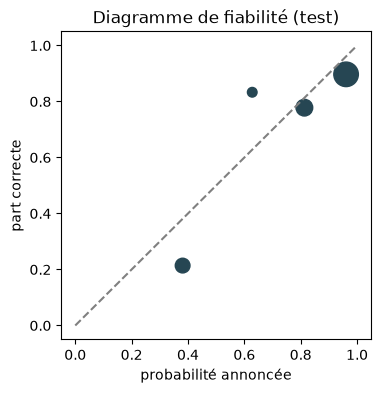

In [4]:
print(f"ECE (test) : {rapport_test.expected_calibration_error:.3f}   |   confiance moyenne : {rapport_test.mean_confidence:.3f}   |   exactitude : {rapport_test.accuracy:.3f}")
bins = pd.cut(res_test.proba_max, [0, .5, .7, .9, 1.0])
fiab = res_test.groupby(bins, observed=True).agg(proba_annoncee=("proba_max", "mean"), exactitude=("correct", "mean"), n=("correct", "size")).round(3)
display(fiab)
plt.figure(figsize=(4, 4)); plt.plot([0, 1], [0, 1], "--", color="grey")
plt.scatter(fiab.proba_annoncee, fiab.exactitude, s=fiab.n * 8, color="#264653")
plt.xlabel("probabilité annoncée"); plt.ylabel("part correcte"); plt.title("Diagramme de fiabilité (test)"); plt.show()

On peut corriger une partie de l'écart avec une **température**, ajustée sur **dev** (jamais sur le test), puis appliquée au test sans relancer le modèle :

In [5]:
dev = at.lire("dev.csv")
rapport_dev, res_dev = at.evaluer(modele, dev, at.OPTIONS)
temperature, _ = rapport_dev.calibrate()
test_recal = rapport_test.rescale(temperature)
print(f"Température ajustée sur dev : {temperature:.3f}")
print(f"ECE test avant : {rapport_test.expected_calibration_error:.3f}  →  après : {test_recal.expected_calibration_error:.3f}  (l'exactitude ne change pas)")
if test_recal.expected_calibration_error > rapport_test.expected_calibration_error:
    print(f"→ Ici la recalibration apprise sur dev EMPIRE la calibration du test : dev ({len(dev)} messages) est trop petit, "
          "et le modèle y réussit mieux que sur le test. Une température ne se transporte pas toute seule : il faut la vérifier.")
else:
    print("→ La température apprise sur dev améliore aussi le test : elle se transporte ici.")

Durée estimée : ≈ 10 s pour 63 messages.


décisions:   0%|          | 0/63 [00:00<?, ?it/s]

63 messages évalués en 10.1 s (161 ms/message)
Température ajustée sur dev : 0.673
ECE test avant : 0.102  →  après : 0.150  (l'exactitude ne change pas)
→ Ici la recalibration apprise sur dev EMPIRE la calibration du test : dev (63 messages) est trop petit, et le modèle y réussit mieux que sur le test. Une température ne se transporte pas toute seule : il faut la vérifier.


## 3. La politique : automatiser ou passer à un humain ?
Règle : si la **marge** (proba du 1er − proba du 2e) est **≥ seuil**, on route automatiquement ; sinon un humain lit le message.
- Seuil 0 : tout est automatisé, avec toutes les erreurs.
- Seuil élevé : très peu d'erreurs, mais les humains lisent beaucoup de messages.

**On choisit le seuil sur dev**, puis on vérifie sur le test.

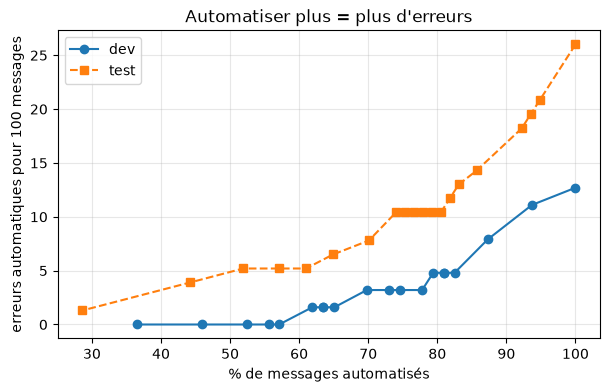

,seuil_marge,automatise_%,vers_humain,exactitude_auto_%,erreurs_auto,erreurs_pour_100_messages
0,0.00,100.0,0,87.3,8,12.7
1,0.05,93.7,4,88.1,7,11.1
2,0.10,87.3,8,90.9,5,7.9
3,0.15,82.5,11,94.2,3,4.8
4,0.20,81.0,12,94.1,3,4.8
5,0.25,81.0,12,94.1,3,4.8
6,0.30,79.4,13,94.0,3,4.8
7,0.35,77.8,14,95.9,2,3.2
8,0.40,74.6,16,95.7,2,3.2
9,0.45,73.0,17,95.7,2,3.2


In [6]:
courbe_dev = at.courbe_selective(rapport_dev)
courbe_test = at.courbe_selective(rapport_test)
fig, ax = plt.subplots(figsize=(7, 4))
for c, nom, style in ((courbe_dev, "dev", "-o"), (courbe_test, "test", "--s")):
    ax.plot(c["automatise_%"], c["erreurs_pour_100_messages"], style, label=nom)
ax.set_xlabel("% de messages automatisés"); ax.set_ylabel("erreurs automatiques pour 100 messages"); ax.legend(); ax.grid(alpha=.3)
plt.title("Automatiser plus = plus d'erreurs"); plt.show()
courbe_dev

### Chaque table choisit son seuil
La réponse n'est ni « tout » ni « rien » : c'est un **seuil** de marge, et la règle qui va avec s'appelle une **politique** de décision.
Déplacez le curseur (s'il ne s'affiche pas, modifiez `SEUIL` dans la cellule suivante). Questions pour la table :
- Combien coûte une **erreur** (un client mal routé, qui attend, qui se plaint) ?
- Combien coûte un message **lu par un humain** ?
- Quel seuil accepteriez-vous en production ?

In [7]:
def montrer(seuil=0.5):
    s = rapport_dev.selective(min_margin=seuil)
    err = s.automated - s.correct
    print(f"Seuil {seuil:.2f} sur DEV → automatisé {s.automation_rate:.0%} ({s.automated}/{s.total}), "
          f"vers humain {s.total - s.automated}, erreurs automatiques {err} "
          f"({'—' if s.accuracy is None else f'{s.accuracy:.1%} d’exactitude sur la part automatisée'})")
try:
    import ipywidgets as w
    w.interact(montrer, seuil=w.FloatSlider(min=0, max=0.95, step=0.05, value=0.5, description="seuil"))
except ImportError:
    montrer(0.5)

interactive(children=(FloatSlider(value=0.5, description='seuil', max=0.95, step=0.05), Output()), _dom_classe…

In [8]:
SEUIL = 0.5   # <-- la valeur choisie par votre table (sur dev !)

for nom, rap in (("dev", rapport_dev), ("TEST scellé", rapport_test)):
    s = rap.selective(min_margin=SEUIL)
    print(f"{nom:<12} seuil {SEUIL:.2f} : automatisé {s.automation_rate:.1%}, exactitude automatique "
          f"{'—' if s.accuracy is None else f'{s.accuracy:.1%}'}, erreurs {s.automated - s.correct}/{s.total}, vers humain {s.total - s.automated}")

dev          seuil 0.50 : automatisé 69.8%, exactitude automatique 95.5%, erreurs 2/63, vers humain 19
TEST scellé  seuil 0.50 : automatisé 76.6%, exactitude automatique 86.4%, erreurs 8/77, vers humain 18


### Pourquoi le test est-il moins bon que dev ?
Comparez l'exactitude dev (bloc 4) et test (plus haut), puis les erreurs au seuil choisi. Trois raisons possibles, toutes à dire à voix haute :
1. **On a écrit les options en regardant dev** : elles sont un peu « ajustées » à ces messages-là.
2. **Petits échantillons** : quelques messages de plus ou de moins font bouger le score de plusieurs points (voir l'intervalle).
3. **Le seuil choisi sur dev ne garantit pas le même taux d'erreur ailleurs** : c'est précisément pour ça que le test scellé existe.

## 4. La politique, en code
C'est tout ce qu'il faut mettre en production, plus un journal (identifiant du modèle, choix, marge, raison).

In [9]:
for m in ["Bonjour, je constate un débit de 89,90 € alors que je n'ai rien commandé.",
          "Internet coupé depuis une semaine, je ne paierai pas ce mois-ci et je réfléchis à partir",
          "SVP rappelez-moi, c'est urgent",
          "colis pas reçu"]:
    service, raison = at.router(modele, m, seuil=SEUIL)
    print(f"→ {service:<12} {raison:<70} | {m}")

→ facturation  automatique (marge 0.98)                                               | Bonjour, je constate un débit de 89,90 € alors que je n'ai rien commandé.


→ facturation  automatique (marge 0.98)                                               | Internet coupé depuis une semaine, je ne paierai pas ce mois-ci et je réfléchis à partir


→ humain       incertain (marge 0.09, hésite entre resiliation et autre)              | SVP rappelez-moi, c'est urgent


→ livraison    automatique (marge 0.95)                                               | colis pas reçu


**À retenir**
- Un chiffre sans intervalle de confiance ne veut presque rien dire avec moins de quelques centaines d'exemples.
- Les probabilités brutes ne sont pas une confiance : on les **mesure** et on les **recalibre** sur dev.
- La politique (le seuil) est un **choix métier**, fait sur dev et **confirmé une fois** sur le test scellé.

---
**Étape 5, point de contrôle** (`missions/5_politique_de_decision/MISSION.md`) : le même objectif, à atteindre comme vous voulez (ce notebook, la commande `atelier`, ou un script).
Vérification sur dev : `atelier verifier 5` dans un terminal, ou la cellule ci-dessous.

In [10]:
from pathlib import Path
from atelier.missions import preparer, verifier
preparer(Path("../travail"))   # crée travail/ avec les fichiers de départ s'ils manquent (n'écrase rien)
print(verifier(5, globals().get("modele"), Path("../travail")).texte())   # réutilise le modèle déjà chargé

Étape 5 — Choisir une politique (bloc 5)
  ✅ un seuil de marge entre 0 et 1 (0.0)
  ✅ votre tolérance : erreurs_max_pour_100 (5)
  ❌ sur dev : 12.7 erreurs automatiques pour 100 messages ≤ 5
  ✅ sur dev : au moins 50 % automatisé (100%, 0 vers un humain)
  Pas encore : relisez les indices de MISSION.md, un à la fois (1, puis 2, puis 3).
